<a href="https://colab.research.google.com/github/GopalKrishna-India/Geospatial/blob/master/SpectralLib-Trees/Mango_SpectralLib_Sentinel2_Updated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ==============================================================================
# 1. INITIALIZATION & SETUP
# ==============================================================================
import os
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ee
from google.colab import files

try:
    ee.Initialize(project='eeciforicraf')
    print("Earth Engine initialized successfully.")
except Exception as e:
    print("Initializing EE with authentication prompt...")
    ee.Authenticate()
    ee.Initialize(project='eeciforicraf')

# ==============================================================================
# 2. USER CONFIGURATION & ASSETS
# ==============================================================================
SAMPLE_ASSET = 'projects/eeciforicraf/assets/SpectralLib/Mango/Mango_LatLong_CSV'
SAMPLE_ID_FIELD = 'SN'
SPECIES_FIELD = 'TreeSpecies'
FIELD_DATE_FIELD = 'Date'
MATCH_WINDOW_DAYS = 45

# Native S2 Bands & Derived Indices Wavelengths
BANDS_10M = ['B2', 'B3', 'B4', 'B8']
BANDS_20M = ['B5', 'B6', 'B7', 'B8A', 'B11', 'B12']
CORE_BANDS = BANDS_10M + BANDS_20M
WAVELENGTHS = [490, 560, 665, 705, 740, 783, 842, 865, 1610, 2190]

# Spatial Boundary Assets
ACZ_ASSET = 'users/GEOINFORMERS/AgroClimaticZones/Agro-ClimateZone_WGS84'
ACZ_BOUNDS = ee.FeatureCollection(ACZ_ASSET)
GAUL_DISTRICTS = ee.FeatureCollection('FAO/GAUL/2015/level2')

# ==============================================================================
# 3. GEOMETRY RECONSTRUCTION & S2 PREPROCESSING
# ==============================================================================
raw_samples = ee.FeatureCollection(SAMPLE_ASSET)

def reconstruct_geometry(feature):
    props = feature.propertyNames()

    lat_keys = ee.List(['Latitude', 'latitude', 'lat', 'Lat', 'LAT'])
    lon_keys = ee.List(['Longitude', 'longitude', 'lon', 'Long', 'lng', 'LON'])

    lat_match = lat_keys.map(lambda k: ee.Algorithms.If(props.contains(k), k, None)).removeAll([None])
    lon_match = lon_keys.map(lambda k: ee.Algorithms.If(props.contains(k), k, None)).removeAll([None])

    lat_val = ee.Algorithms.If(lat_match.size().gt(0), feature.get(lat_match.get(0)), None)
    lon_val = ee.Algorithms.If(lon_match.size().gt(0), feature.get(lon_match.get(0)), None)

    is_valid = ee.Algorithms.If(lat_val, ee.Algorithms.If(lon_val, True, False), False)

    point_geom = ee.Algorithms.If(
        is_valid,
        ee.Geometry.Point([ee.Number.parse(ee.String(lon_val)), ee.Number.parse(ee.String(lat_val))]),
        None
    )
    return feature.setGeometry(ee.Geometry(point_geom)).set('is_valid_geom', is_valid)

samples = raw_samples.map(reconstruct_geometry)\
    .filter(ee.Filter.eq('is_valid_geom', True))\
    .filter(ee.Filter.notNull([SAMPLE_ID_FIELD, FIELD_DATE_FIELD]))

def mask_s2_sr(image):
    scl = image.select('SCL')
    clear_mask = scl.neq(0).And(scl.neq(1)).And(scl.neq(2)).And(scl.neq(3))\
        .And(scl.neq(7)).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10)).And(scl.neq(11))

    return image.select(CORE_BANDS).multiply(0.0001).updateMask(clear_mask)\
        .copyProperties(image, ['system:time_start', 'CLOUDY_PIXEL_PERCENTAGE'])

S2 = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')\
    .filterBounds(samples.geometry())\
    .map(mask_s2_sr)

# ==============================================================================
# 4. SPATIAL ANNOTATION & FEATURE EXTRACTION
# ==============================================================================
def attach_spatial_regions(feature):
    geom = feature.geometry()

    acz_match = ACZ_BOUNDS.filterBounds(geom).first()
    acz_name = ee.Algorithms.If(acz_match, ee.Feature(acz_match).get('ACZ_NAME'), 'UNKNOWN_ACZ')

    gaul_match = GAUL_DISTRICTS.filterBounds(geom).first()
    district_name = ee.Algorithms.If(gaul_match, ee.Feature(gaul_match).get('ADM2_NAME'), 'UNKNOWN_DISTRICT')

    return feature.set({
        'AgroClimatic_Zone': acz_name,
        'District': district_name
    })

samples_annotated = samples.map(attach_spatial_regions)

def extract_sample_record_server(feature):
    geom = feature.geometry().buffer(20)
    date_str = ee.String(feature.get(FIELD_DATE_FIELD))
    field_date = ee.Date.parse('dd-MM-yyyy', date_str)

    start = field_date.advance(-MATCH_WINDOW_DAYS, 'day')
    end = field_date.advance(MATCH_WINDOW_DAYS + 1, 'day')

    best_scene = S2.filterDate(start, end)\
        .filterBounds(geom)\
        .sort('CLOUDY_PIXEL_PERCENTAGE')\
        .first()

    has_scene = ee.Algorithms.If(ee.Algorithms.IsEqual(best_scene, None), False, True)
    img = ee.Image(best_scene)

    # Derive Vegetation & Moisture Indices
    ndvi = img.normalizedDifference(['B8', 'B4']).rename('NDVI')
    ndre = img.normalizedDifference(['B8A', 'B5']).rename('NDRE')
    ndmi = img.normalizedDifference(['B8A', 'B11']).rename('NDMI_Moisture')

    full_img = img.select(CORE_BANDS).addBands([ndvi, ndre, ndmi])

    spatial_stats = ee.Algorithms.If(
        has_scene,
        full_img.reduceRegion(
            reducer=ee.Reducer.median(),
            geometry=geom,
            scale=10,
            maxPixels=1e8,
            tileScale=16
        ),
        ee.Dictionary({})
    )

    quality_info = ee.Dictionary({
        'record_status': ee.Algorithms.If(has_scene, 'OK', 'NO_SUITABLE_SCENE'),
        'acquisition_date': ee.Algorithms.If(has_scene, ee.Date(img.get('system:time_start')).format('YYYY-MM-dd'), 'NO_MATCH'),
        'scene_cloud_pct': ee.Algorithms.If(has_scene, img.get('CLOUDY_PIXEL_PERCENTAGE'), 100)
    })

    return feature.toDictionary().combine(quality_info, True).combine(spatial_stats, True)

processed_fc = samples_annotated.map(lambda f: ee.Feature(None, extract_sample_record_server(f)))

# ==============================================================================
# 5. ASYNCHRONOUS BATCH EXPORT TO GOOGLE DRIVE
# ==============================================================================
task_description = 'Mango_Spectral_Library_Batch_Export'

task = ee.batch.Export.table.toDrive(
    collection=processed_fc,
    description=task_description,
    folder='Spec-Lib/Mango',
    fileNamePrefix='Mango_Spectral_Library_Batch_Export',
    fileFormat='CSV'
)

task.start()
print("Submitted Earth Engine Batch Export Task.")
print("Waiting for task completion on background server...")

while task.active():
    status = task.status()
    print(f"  Current Status: {status.get('state')} | Step: {status.get('description')}")
    time.sleep(15)

final_status = task.status()
print(f"Task Execution Finished with State: {final_status.get('state')}")

if final_status.get('state') == 'COMPLETED':
    print("Spectral library successfully computed and exported to Google Drive (/Spec-Lib/Mango/)!")


Earth Engine initialized successfully.
Submitted Earth Engine Batch Export Task.
Waiting for task completion on background server...
  Current Status: READY | Step: Mango_Spectral_Library_Batch_Export
  Current Status: RUNNING | Step: Mango_Spectral_Library_Batch_Export
  Current Status: RUNNING | Step: Mango_Spectral_Library_Batch_Export
  Current Status: RUNNING | Step: Mango_Spectral_Library_Batch_Export
  Current Status: RUNNING | Step: Mango_Spectral_Library_Batch_Export
  Current Status: RUNNING | Step: Mango_Spectral_Library_Batch_Export
  Current Status: RUNNING | Step: Mango_Spectral_Library_Batch_Export
  Current Status: RUNNING | Step: Mango_Spectral_Library_Batch_Export
  Current Status: RUNNING | Step: Mango_Spectral_Library_Batch_Export
  Current Status: RUNNING | Step: Mango_Spectral_Library_Batch_Export
  Current Status: RUNNING | Step: Mango_Spectral_Library_Batch_Export
  Current Status: RUNNING | Step: Mango_Spectral_Library_Batch_Export
  Current Status: RUNNING | S

NameError: name 'df' is not defined

<Figure size 1000x600 with 0 Axes>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Total valid spectra analyzed: 447
Normal canopy spectra identified: 424
Outlier spectra flagged and removed: 23


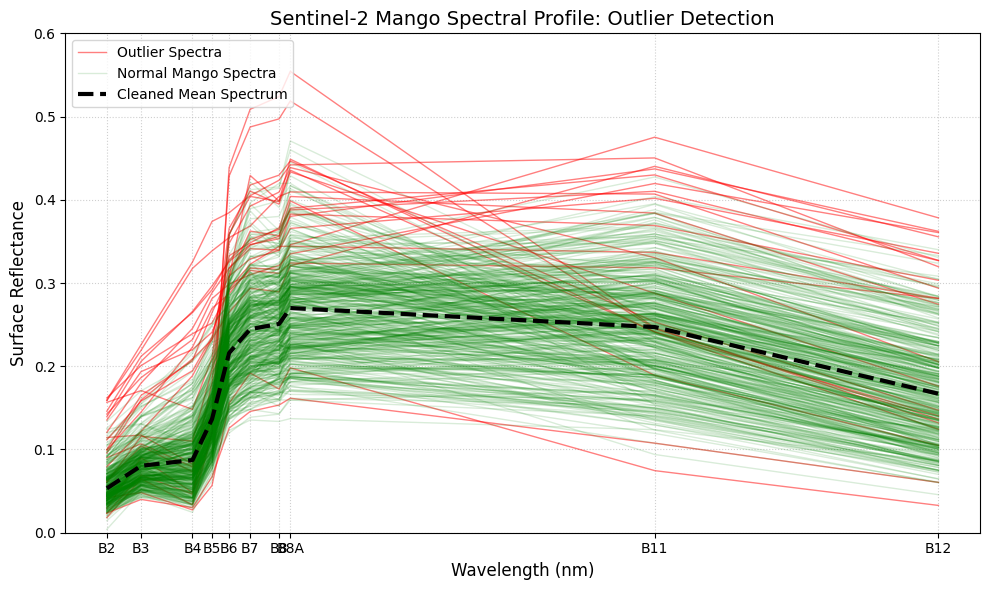

Exported cleaned library to: /content/drive/MyDrive/Spec-Lib/Mango/Mango_Spectral_Library_Cleaned.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from google.colab import drive

# ==============================================================================
# 1. MOUNT GOOGLE DRIVE & LOAD FILE
# ==============================================================================
drive.mount('/content/drive')

file_path = "/content/drive/MyDrive/Spec-Lib/Mango/Mango_Spectral_Library_Batch_Export.csv"
df = pd.read_csv(file_path)

# Filter out unmapped scenes first
if 'record_status' in df.columns:
    df = df[df['record_status'] == 'OK'].copy()

# Automatically identify spectral band columns (handles 'B2' or 'B2_median')
core_bands = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']
spectral_cols = []
for band in core_bands:
    if band in df.columns:
        spectral_cols.append(band)
    elif f"{band}_median" in df.columns:
        spectral_cols.append(f"{band}_median")

# Convert spectral columns to numeric values
df[spectral_cols] = df[spectral_cols].apply(pd.to_numeric, errors='coerce')
df = df.dropna(subset=spectral_cols).reset_index(drop=True)

# ==============================================================================
# 2. OUTLIER DETECTION (ISOLATION FOREST + BOTANICAL RULE CHECKS)
# ==============================================================================
# Method A: Isolation Forest on Core Spectral Curves
iso = IsolationForest(contamination=0.05, random_state=42)
df['is_outlier_iso'] = iso.fit_predict(df[spectral_cols]) == -1

# Method B: Botanical Rule Checks for Canopy Vegetation
# Normal vegetation must have NIR > Red (B8 > B4) and reasonable NDVI
nir_col = 'B8_median' if 'B8_median' in df.columns else 'B8'
red_col = 'B4_median' if 'B4_median' in df.columns else 'B4'

df['is_non_veg'] = (df[nir_col] <= df[red_col]) | (df[nir_col] > 0.8) | (df[red_col] > 0.3)

# Combine Outlier Flags
df['is_outlier'] = df['is_outlier_iso'] | df['is_non_veg']

outliers_df = df[df['is_outlier']].copy()
cleaned_df = df[~df['is_outlier']].copy()

print(f"Total valid spectra analyzed: {len(df)}")
print(f"Normal canopy spectra identified: {len(cleaned_df)}")
print(f"Outlier spectra flagged and removed: {len(outliers_df)}")

# ==============================================================================
# 3. PLOT NORMAL VS OUTLIER SPECTRA
# ==============================================================================
wavelengths = [490, 560, 665, 705, 740, 783, 842, 865, 1610, 2190]
plt.figure(figsize=(10, 6))

# Plot Outliers in Red
for i, (_, row) in enumerate(outliers_df.iterrows()):
    plt.plot(wavelengths, row[spectral_cols], color='red', alpha=0.5,
             linewidth=1, label='Outlier Spectra' if i == 0 else "")

# Plot Cleaned Spectra in Green
for i, (_, row) in enumerate(cleaned_df.iterrows()):
    plt.plot(wavelengths, row[spectral_cols], color='green', alpha=0.15,
             linewidth=1, label='Normal Mango Spectra' if i == 0 else "")

# Mean Cleaned Spectrum
mean_clean = cleaned_df[spectral_cols].mean()
plt.plot(wavelengths, mean_clean, color='black', linewidth=3, linestyle='--', label='Cleaned Mean Spectrum')

plt.title('Sentinel-2 Mango Spectral Profile: Outlier Detection', fontsize=14)
plt.xlabel('Wavelength (nm)', fontsize=12)
plt.ylabel('Surface Reflectance', fontsize=12)
plt.xticks(wavelengths, labels=['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12'])
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left')
plt.ylim(0, 0.6)

plt.tight_layout()
plt.show()

# Export Cleaned Library back to Drive
cleaned_output_path = "/content/drive/MyDrive/Spec-Lib/Mango/Mango_Spectral_Library_Cleaned.csv"
cleaned_df.to_csv(cleaned_output_path, index=False)
print(f"Exported cleaned library to: {cleaned_output_path}")

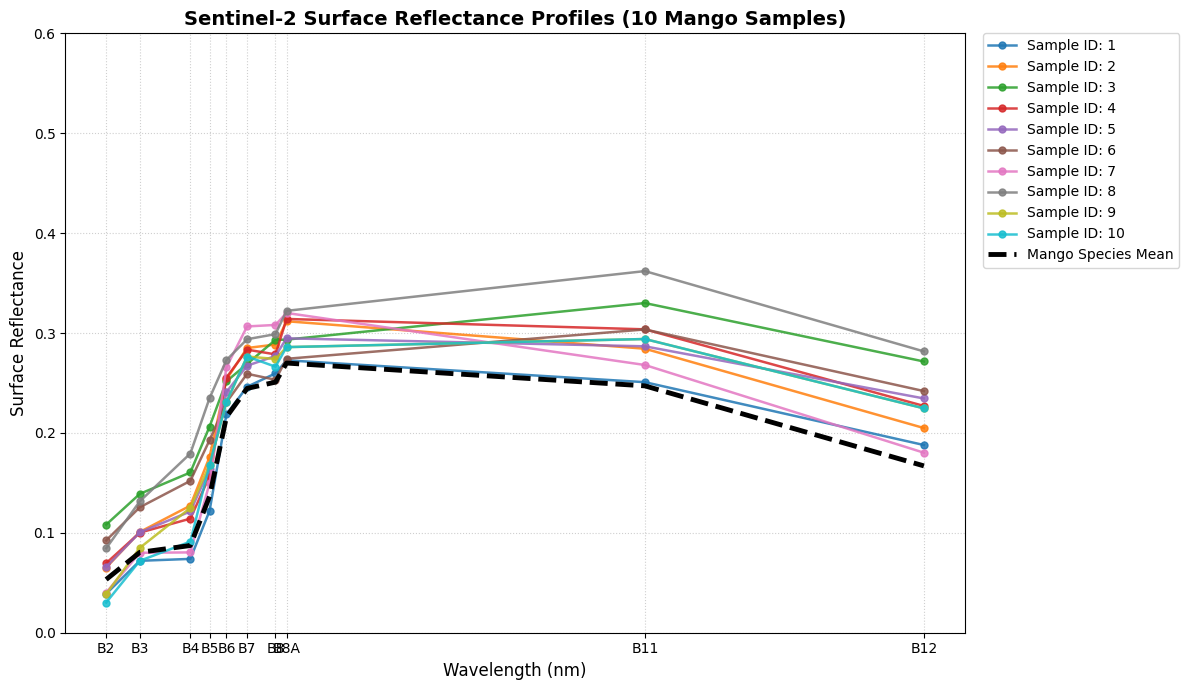

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==============================================================================
# SPECTRAL PROFILE PLOT FOR 10 SAMPLE POINTS WITH LEGENDS
# ==============================================================================
# Use cleaned dataframe if available, otherwise read from cleaned CSV
try:
    plot_df = cleaned_df.copy()
except NameError:
    plot_df = pd.read_csv("/content/drive/MyDrive/Spec-Lib/Mango/Mango_Spectral_Library_Cleaned.csv")

# Ensure spectral columns and wavelengths align
core_bands = ['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12']
wavelengths = [490, 560, 665, 705, 740, 783, 842, 865, 1610, 2190]

profile_bands = [b if b in plot_df.columns else f"{b}_median" for b in core_bands]

plt.figure(figsize=(12, 7))

# Distinct color palette for 10 individual samples
colors = plt.cm.tab10(np.linspace(0, 1, 10))

# Identify sample ID column
sample_id_col = 'SN' if 'SN' in plot_df.columns else plot_df.columns[0]

# Plot first 10 individual sample curves
num_samples_to_plot = min(10, len(plot_df))
for i in range(num_samples_to_plot):
    sample_row = plot_df.iloc[i]
    spectrum = [pd.to_numeric(sample_row.get(b), errors='coerce') for b in profile_bands]
    sample_id = sample_row.get(sample_id_col, f"Point {i+1}")

    plt.plot(
        wavelengths,
        spectrum,
        marker='o',
        markersize=5,
        linewidth=1.8,
        color=colors[i],
        alpha=0.85,
        label=f"Sample ID: {sample_id}"
    )

# Overlay species overall mean curve
df_bands = plot_df[profile_bands].apply(pd.to_numeric, errors='coerce')
mean_spectrum = df_bands.mean()

plt.plot(
    wavelengths,
    mean_spectrum,
    color='black',
    linewidth=3.5,
    linestyle='--',
    label='Mango Species Mean'
)

# Plot formatting and custom legend placement outside graph area
plt.title('Sentinel-2 Surface Reflectance Profiles (10 Mango Samples)', fontsize=14, fontweight='bold')
plt.xlabel('Wavelength (nm)', fontsize=12)
plt.ylabel('Surface Reflectance', fontsize=12)
plt.xticks(wavelengths, labels=['B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B11', 'B12'])
plt.grid(True, linestyle=':', alpha=0.6)
plt.ylim(0, 0.6)

# Place legend cleanly on the right side of the chart
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0, frameon=True)

plt.tight_layout()
plt.show()